# Integrated Urban Risk Analytics and Resource Prioritization

This notebook combines the completed **flood, heat, infrastructure and road** analyses into one transparent urban screening workflow.

**Important:** the final score is a screening/resource-prioritization indicator, not a validated citywide risk prediction model.

The notebook preserves the meaning of each module:
- Flood: observed rainfall and historical-event evidence.
- Heat: measured temperature/UHI and exploratory spatial analysis.
- Infrastructure: descriptive spatial clusters and mapped-asset availability.
- Roads: representative-point density and road-segment information.

No fabricated risk labels are created. Missing source coverage remains missing rather than being treated as zero risk.

## Workflow

1. Load the completed module outputs.
2. Use the completed 1-km infrastructure/road grid as the spatial backbone.
3. Aggregate flood and heat observations to the same grid.
4. Create normalized component indicators.
5. Combine them into a transparent **Integrated Urban Priority Score (IUPS)**.
6. Add data-availability/confidence flags.
7. Export dashboard-ready CSV and JSON.

The question answered is:

> Which mapped areas deserve closer investigation or resource-planning attention first, given the available evidence?

In [120]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(r"C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics")
DATA_ROOT = PROJECT_ROOT / "data" / "processed"
OUTPUT_ROOT = DATA_ROOT / "integrated_urban_risk"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

GRID_SIZE_KM = 1.0
RANDOM_STATE = 42

print("Project root:", PROJECT_ROOT)
print("Output:", OUTPUT_ROOT)

Project root: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics
Output: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\integrated_urban_risk


## 1. Locate completed module outputs

The loader checks the known paths from the completed analyses and then searches `data/processed` for heat CSVs.

If your MODIS/Yale CSV names differ, the diagnostic cell prints candidate files instead of silently selecting an unrelated dataset.

In [121]:
def first_existing(paths):
    for p in paths:
        if p.exists():
            return p
    return None

def recursive_find(names):
    for p in DATA_ROOT.rglob("*.csv"):
        if p.name.lower() in {n.lower() for n in names}:
            return p
    return None

sources = {
    "infrastructure_grid": first_existing([
        DATA_ROOT / "infrastructure" / "integrated_infrastructure_road_grid_1km.csv",
        DATA_ROOT / "infrastructure" / "integrated_infrastructure_experiments" / "integrated_infrastructure_road_grid_1km.csv",
        DATA_ROOT / "integrated_infrastructure_road_grid_1km.csv",
    ]),

    "infrastructure_dashboard": first_existing([
        DATA_ROOT / "infrastructure" / "integrated_infrastructure_experiments" /
        "clustering_experiments" / "integrated_grid_final_kmeans_2_dashboard_ready.csv",
    ]),

    "roads": first_existing([
        DATA_ROOT / "infrastructure" / "roads_processed.csv",
    ]),

    "rainfall": first_existing([
        DATA_ROOT / "flood" / "hyderabad_rainfall.csv",
    ]),

    "historical_flood": first_existing([
        DATA_ROOT / "flood" / "hyderabad_historical_flood_events.csv",
    ]),

    "modis": first_existing([
        DATA_ROOT / "heat" / "hyderabad_modis_heat.csv",
    ]),

    "yale": first_existing([
        DATA_ROOT / "heat" / "hyderabad_yale_heat.csv",
    ]),
}

for k, v in sources.items():
    print(f"{k:24s} -> {v}")

infrastructure_grid      -> C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments\integrated_infrastructure_road_grid_1km.csv
infrastructure_dashboard -> C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments\clustering_experiments\integrated_grid_final_kmeans_2_dashboard_ready.csv
roads                    -> C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\roads_processed.csv
rainfall                 -> C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\hyderabad_rainfall.csv
historical_flood         -> C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\hyderabad_historical_flood_events.csv
modis                    -> C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\hyderabad_modis_heat.csv
yale                     -> C:\Users\sanaf\OneDrive\Desktop\ur

In [122]:
print("Candidate heat-related CSV files:")
for p in sorted(DATA_ROOT.rglob("*.csv")):
    n = p.name.lower()
    if any(x in n for x in ["modis", "yale", "uhi", "heat", "temperature"]):
        print(p)

Candidate heat-related CSV files:
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\hyderabad_modis_heat.csv
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\hyderabad_yale_heat.csv
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\modis_experiments\modis_kmeans_approach_comparison.csv
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\modis_experiments\modis_kmeans_pseudolabel_classifier_comparison.csv
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\modis_experiments\modis_legacy_category_profile.csv
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\modis_experiments\modis_regression_holdout_evaluation.csv
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\modis_experiments\modis_regression_spatial_cv_results.csv
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\modis_experiments\modis_spatial_thermal_c

## 2. Load and audit the datasets

In [123]:
def load_csv(key):
    path = sources.get(key)
    if path is None:
        print(f"{key}: NOT FOUND")
        return None
    df = pd.read_csv(path)
    print(f"\n[{key}] {df.shape}")
    print(path)
    print(list(df.columns))
    return df

infra = load_csv("infrastructure_grid")
infra_dashboard = load_csv("infrastructure_dashboard")
roads = load_csv("roads")
rainfall = load_csv("rainfall")
historical_flood = load_csv("historical_flood")
modis = load_csv("modis")
yale = load_csv("yale")


[infrastructure_grid] (791, 26)
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments\integrated_infrastructure_road_grid_1km.csv
['grid_id', 'grid_x', 'grid_y', 'infra_building_count', 'infra_fire_station_count', 'infra_hospital_count', 'road_representative_point_count', 'road_segment_length_sum_km', 'mean_recorded_segment_length_km', 'unique_road_types', 'roadtype_motorway_count', 'roadtype_primary_count', 'roadtype_residential_count', 'roadtype_secondary_count', 'roadtype_tertiary_count', 'roadtype_trunk_count', 'roadtype_unclassified_count', 'cell_center_x_km', 'cell_center_y_km', 'cell_center_longitude', 'cell_center_latitude', 'total_infrastructure_records', 'total_road_type_records', 'low_infrastructure_records', 'low_road_point_count', 'investigation_flag']

[infrastructure_dashboard] (791, 33)
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experimen


[roads] (93437, 8)
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\roads_processed.csv
['osm_id', 'road_name', 'road_type', 'maxspeed', 'oneway', 'latitude', 'longitude', 'length_km']

[rainfall] (84, 4)
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\hyderabad_rainfall.csv
['date', 'latitude', 'longitude', 'rainfall_mm']

[historical_flood] (40, 11)
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\flood\hyderabad_historical_flood_events.csv
['UEI', 'Start Date', 'End Date', 'Start_Date_Parsed', 'End_Date_Parsed', 'Main Cause', 'Districts', 'State', 'Duration(Days)', 'Human fatality', 'Human injured']

[modis] (1326, 5)
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\hyderabad_modis_heat.csv
['pixel_id', 'latitude', 'longitude', 'daytime_temp_c', 'nighttime_temp_c']

[yale] (5939, 5)
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\heat\hyderabad_yale_heat.csv
['

## 3. Helper functions for spatial integration

A local equirectangular approximation is sufficient for this common-grid screening layer. It is not a road-routing calculation.

In [124]:

def find_col(df, candidates):
    if df is None:
        return None

    lookup = {str(c).lower().strip(): c for c in df.columns}

    for candidate in candidates:
        key = candidate.lower().strip()
        if key in lookup:
            return lookup[key]

    return None


def coordinate_columns(df):
    if df is None:
        return None, None

    lat_col = find_col(
        df, ["latitude", "lat", "cell_center_latitude"]
    )
    lon_col = find_col(
        df, ["longitude", "lon", "lng", "cell_center_longitude"]
    )

    return lat_col, lon_col


print("Spatial helper functions loaded.")


Spatial helper functions loaded.


## 4. Prepare the infrastructure/road backbone

The completed integrated grid is used as the master grid. It contains the 791 common cells from the earlier infrastructure-road integration.

In [125]:

from scipy.spatial import cKDTree

if infra is None:
    raise FileNotFoundError(
        "The integrated infrastructure-road grid was not found."
    )

required = [
    "grid_id",
    "cell_center_latitude",
    "cell_center_longitude",
    "infra_building_count",
    "infra_hospital_count",
    "road_representative_point_count",
    "road_segment_length_sum_km",
    "unique_road_types"
]

missing = [c for c in required if c not in infra.columns]

if missing:
    raise ValueError(f"Missing required backbone columns: {missing}")

backbone = infra.copy().reset_index(drop=True)

if backbone["grid_id"].duplicated().any():
    raise ValueError("Duplicate grid_id values found in master grid.")

# Convert all coordinates using one common local projection.
reference_latitude = backbone["cell_center_latitude"].mean()

KM_PER_DEGREE_LAT = 111.32
KM_PER_DEGREE_LON = (
    111.32 * np.cos(np.radians(reference_latitude))
)


def coordinates_to_km(latitude, longitude):
    x = np.asarray(longitude) * KM_PER_DEGREE_LON
    y = np.asarray(latitude) * KM_PER_DEGREE_LAT
    return np.column_stack([x, y])


grid_coordinates = coordinates_to_km(
    backbone["cell_center_latitude"].to_numpy(),
    backbone["cell_center_longitude"].to_numpy()
)

grid_tree = cKDTree(grid_coordinates)

# Approximate nearest-grid-centre assignment tolerance.
MAX_ASSIGNMENT_DISTANCE_KM = 0.75


def aggregate_to_master_grid(
    df,
    dataset_name,
    value_column,
    output_prefix
):
    if df is None:
        print(f"{dataset_name}: dataset not available.")
        return pd.DataFrame()

    lat_col, lon_col = coordinate_columns(df)

    if lat_col is None or lon_col is None:
        print(f"{dataset_name}: latitude/longitude columns missing.")
        return pd.DataFrame()

    if value_column is None or value_column not in df.columns:
        print(f"{dataset_name}: measurement column missing.")
        return pd.DataFrame()

    source = df.copy()

    source[lat_col] = pd.to_numeric(
        source[lat_col], errors="coerce"
    )
    source[lon_col] = pd.to_numeric(
        source[lon_col], errors="coerce"
    )
    source[value_column] = pd.to_numeric(
        source[value_column], errors="coerce"
    )

    source = source.dropna(
        subset=[lat_col, lon_col, value_column]
    ).copy()

    valid_coordinates = (
        source[lat_col].between(-90, 90)
        & source[lon_col].between(-180, 180)
    )

    source = source.loc[valid_coordinates].copy()

    if source.empty:
        print(f"{dataset_name}: no valid observations.")
        return pd.DataFrame()

    source_coordinates = coordinates_to_km(
        source[lat_col].to_numpy(),
        source[lon_col].to_numpy()
    )

    distances, nearest_indices = grid_tree.query(
        source_coordinates,
        k=1
    )

    accepted = distances <= MAX_ASSIGNMENT_DISTANCE_KM

    assigned = source.loc[accepted].copy()

    assigned["grid_id"] = (
        backbone.iloc[nearest_indices[accepted]]["grid_id"].to_numpy()
    )

    result = (
        assigned.groupby("grid_id")[value_column]
        .agg(["mean", "max", "count"])
        .reset_index()
        .rename(columns={
            "mean": f"{output_prefix}_mean",
            "max": f"{output_prefix}_max",
            "count": f"{output_prefix}_observation_count"
        })
    )

    print(f"\n{dataset_name} assignment results")
    print("Valid observations:", len(source))
    print("Assigned observations:", int(accepted.sum()))
    print("Rejected observations:", int((~accepted).sum()))
    print("Grid cells reached:", result["grid_id"].nunique())
    print(
        "Grid coverage:",
        round(result["grid_id"].nunique() / len(backbone) * 100, 2),
        "%"
    )

    return result


integrated = backbone.copy()

print("Master grid shape:", backbone.shape)
print("Unique grid cells:", backbone["grid_id"].nunique())
print("Reference latitude:", reference_latitude)
print("Assignment tolerance:", MAX_ASSIGNMENT_DISTANCE_KM, "km")
print("Common spatial assignment function ready.")


Master grid shape: (791, 26)
Unique grid cells: 791
Reference latitude: 17.428600763299418
Assignment tolerance: 0.75 km
Common spatial assignment function ready.


## 5. Flood evidence layer

The rainfall data contain observations on specific dates, not verified future flood labels. Therefore the spatial layer uses observed rainfall intensity as **flood-related evidence**.

Historical event data are also retained for audit. They are spatially joined only if usable latitude/longitude columns are present.

In [126]:

flood_grid = pd.DataFrame()

if rainfall is not None:
    rainfall_value_col = find_col(
        rainfall,
        [
            "rainfall_mm",
            "rainfall",
            "precipitation",
            "precipitation_mm"
        ]
    )

    print("Rainfall measurement column:", rainfall_value_col)

    if rainfall_value_col is not None:
        flood_grid = aggregate_to_master_grid(
            df=rainfall,
            dataset_name="Rainfall",
            value_column=rainfall_value_col,
            output_prefix="flood_rainfall"
        )

if historical_flood is not None:
    hlat, hlon = coordinate_columns(historical_flood)

    print("\nHistorical flood coordinate audit:")
    print("Latitude column:", hlat)
    print("Longitude column:", hlon)

    if hlat is None or hlon is None:
        print(
            "Historical events will remain contextual evidence "
            "and will not be assigned to grid cells."
        )


Rainfall measurement column: rainfall_mm

Rainfall assignment results
Valid observations: 84
Assigned observations: 52
Rejected observations: 32
Grid cells reached: 26
Grid coverage: 3.29 %

Historical flood coordinate audit:
Latitude column: None
Longitude column: None
Historical events will remain contextual evidence and will not be assigned to grid cells.


## 6. Heat evidence layer

The preferred MODIS variable is daytime temperature (`daytime_temp_c`). The preferred Yale variable is daytime UHI (`daytime_uhi`).


The MODIS and Yale datasets are aggregated independently to the common master grid.

- MODIS represents measured daytime land-surface temperature.
- Yale represents daytime urban heat-island intensity.

Both sources are retained separately. Their independently normalized percentile scores are combined where observations are available.

These are exploratory relative heat indicators, not validated heat-risk labels.


In [127]:

# MODIS daytime temperature
modis_value_col = find_col(
    modis,
    [
        "daytime_temp_c",
        "daytime_temperature_c",
        "temperature_c",
        "lst_c"
    ]
)

print("MODIS measurement column:", modis_value_col)

modis_grid = aggregate_to_master_grid(
    df=modis,
    dataset_name="MODIS daytime temperature",
    value_column=modis_value_col,
    output_prefix="modis"
)


# Yale daytime urban heat-island intensity
yale_value_col = find_col(
    yale,
    [
        "daytime_uhi",
        "daytime_uhi_c",
        "uhi",
        "uhi_c"
    ]
)

print("\nYale measurement column:", yale_value_col)

yale_grid = aggregate_to_master_grid(
    df=yale,
    dataset_name="Yale daytime UHI",
    value_column=yale_value_col,
    output_prefix="yale"
)


MODIS measurement column: daytime_temp_c



MODIS daytime temperature assignment results
Valid observations: 1326
Assigned observations: 851
Rejected observations: 475
Grid cells reached: 741
Grid coverage: 93.68 %

Yale measurement column: daytime_uhi

Yale daytime UHI assignment results
Valid observations: 5939
Assigned observations: 5728
Rejected observations: 211
Grid cells reached: 630
Grid coverage: 79.65 %


## 7. Merge the evidence layers

Missing observations remain `NaN`. This is important: no source observation is not the same as zero exposure.

In [128]:

integrated = backbone.copy()

layers = [
    ("Flood rainfall", flood_grid),
    ("MODIS heat", modis_grid),
    ("Yale heat", yale_grid)
]

for layer_name, layer in layers:
    if layer is not None and not layer.empty:
        if layer["grid_id"].duplicated().any():
            raise ValueError(
                f"{layer_name} contains duplicate grid IDs."
            )

        integrated = integrated.merge(
            layer,
            on="grid_id",
            how="left",
            validate="one_to_one"
        )

print("Integrated dataset shape:", integrated.shape)
print("Unique grid cells:", integrated["grid_id"].nunique())

print("\nMerged evidence columns:")
print([
    c for c in integrated.columns
    if c not in backbone.columns
])

assert len(integrated) == len(backbone)
assert integrated["grid_id"].is_unique

print("\nCOMMON MASTER-GRID MERGE VERIFIED.")


Integrated dataset shape: (791, 35)
Unique grid cells: 791

Merged evidence columns:
['flood_rainfall_mean', 'flood_rainfall_max', 'flood_rainfall_observation_count', 'modis_mean', 'modis_max', 'modis_observation_count', 'yale_mean', 'yale_max', 'yale_observation_count']

COMMON MASTER-GRID MERGE VERIFIED.


## 8. Data availability and confidence

Availability is tracked separately from the priority score. This prevents sparse source coverage from being hidden inside a single number.

In [129]:

# Individual source availability
integrated["flood_data_available"] = (
    integrated.get(
        "flood_rainfall_observation_count",
        pd.Series(np.nan, index=integrated.index)
    ).fillna(0).gt(0).astype(int)
)

integrated["modis_data_available"] = (
    integrated.get(
        "modis_observation_count",
        pd.Series(np.nan, index=integrated.index)
    ).fillna(0).gt(0).astype(int)
)

integrated["yale_data_available"] = (
    integrated.get(
        "yale_observation_count",
        pd.Series(np.nan, index=integrated.index)
    ).fillna(0).gt(0).astype(int)
)

integrated["infrastructure_data_available"] = (
    integrated["infra_building_count"].fillna(0)
    + integrated["infra_hospital_count"].fillna(0)
).gt(0).astype(int)

integrated["road_data_available"] = (
    integrated["road_representative_point_count"]
    .fillna(0).gt(0).astype(int)
)

# Five individual data-source indicators.
availability_cols = [
    "flood_data_available",
    "modis_data_available",
    "yale_data_available",
    "infrastructure_data_available",
    "road_data_available"
]

integrated["data_availability_count"] = (
    integrated[availability_cols].sum(axis=1)
)

integrated["data_availability_ratio"] = (
    integrated["data_availability_count"] / len(availability_cols)
)

# Heat is available if either MODIS or Yale has observations.
integrated["heat_data_available"] = (
    (integrated["modis_data_available"] == 1)
    | (integrated["yale_data_available"] == 1)
).astype(int)

# Four main evidence/context components.
confidence_components = [
    "flood_data_available",
    "heat_data_available",
    "infrastructure_data_available",
    "road_data_available"
]

integrated["priority_component_count"] = (
    integrated[confidence_components].sum(axis=1)
)

integrated["priority_confidence"] = np.select(
    [
        integrated["priority_component_count"] == 4,
        integrated["priority_component_count"] == 3,
        integrated["priority_component_count"] == 2,
        integrated["priority_component_count"] == 1
    ],
    [
        "High",
        "Moderate",
        "Limited",
        "Very limited"
    ],
    default="No usable evidence"
)

print("Individual source availability:")
for col in availability_cols:
    print(col, ":", int(integrated[col].sum()), "cells")

print("\nPriority component coverage:")
print(
    integrated["priority_component_count"]
    .value_counts()
    .sort_index()
)

print("\nConfidence distribution:")
print(integrated["priority_confidence"].value_counts())


Individual source availability:
flood_data_available : 26 cells
modis_data_available : 741 cells
yale_data_available : 630 cells
infrastructure_data_available : 412 cells
road_data_available : 763 cells

Priority component coverage:
priority_component_count
1     41
2    363
3    373
4     14
Name: count, dtype: int64

Confidence distribution:
priority_confidence
Moderate        373
Limited         363
Very limited     41
High             14
Name: count, dtype: int64


## 9. Normalize the components

The raw measurements have different units. Percentile-rank scaling puts them on a common 0–1 relative scale.

- Higher rainfall -> stronger flood evidence.
- Higher daytime temperature/UHI -> stronger heat evidence.
- Infrastructure and road values are planning context, not direct risk.

In [130]:

def percentile_score(series):
    series = pd.to_numeric(series, errors="coerce")

    result = pd.Series(
        np.nan,
        index=series.index,
        dtype=float
    )

    valid = series.notna()

    if valid.sum() >= 2:
        result.loc[valid] = series.loc[valid].rank(pct=True)
    elif valid.sum() == 1:
        result.loc[valid] = 0.5

    return result


# -----------------------------------------
# FLOOD EVIDENCE
# -----------------------------------------
if "flood_rainfall_max" in integrated.columns:
    integrated["flood_evidence_score"] = percentile_score(
        integrated["flood_rainfall_max"]
    )
else:
    integrated["flood_evidence_score"] = np.nan


# -----------------------------------------
# MODIS HEAT EVIDENCE
# -----------------------------------------
if "modis_max" in integrated.columns:
    integrated["modis_heat_score"] = percentile_score(
        integrated["modis_max"]
    )
else:
    integrated["modis_heat_score"] = np.nan


# -----------------------------------------
# YALE HEAT EVIDENCE
# -----------------------------------------
if "yale_max" in integrated.columns:
    integrated["yale_heat_score"] = percentile_score(
        integrated["yale_max"]
    )
else:
    integrated["yale_heat_score"] = np.nan


# Combine available MODIS and Yale scores.
heat_score_columns = [
    "modis_heat_score",
    "yale_heat_score"
]

integrated["heat_evidence_score"] = (
    integrated[heat_score_columns].mean(axis=1, skipna=True)
)

# If neither heat source is available, keep heat score missing.
no_heat_data = (
    integrated["modis_heat_score"].isna()
    & integrated["yale_heat_score"].isna()
)

integrated.loc[
    no_heat_data,
    "heat_evidence_score"
] = np.nan


# -----------------------------------------
# RESOURCE CONTEXT GAP INDICATORS
# -----------------------------------------

infrastructure_total = (
    integrated["infra_building_count"].fillna(0)
    + integrated["infra_hospital_count"].fillna(0)
)

infrastructure_mapped_score = percentile_score(
    np.log1p(infrastructure_total)
)

road_mapped_score = percentile_score(
    np.log1p(
        integrated["road_representative_point_count"].fillna(0)
    )
)

# Higher gap score means relatively fewer mapped records.
# This is a mapping-based proxy, not a validated service-adequacy measure.
integrated["infrastructure_gap_score"] = (
    1 - infrastructure_mapped_score
)

integrated["road_representation_gap_score"] = (
    1 - road_mapped_score
)

print("Normalized component scores created.")

print("\nAvailable score columns:")
print([
    "flood_evidence_score",
    "modis_heat_score",
    "yale_heat_score",
    "heat_evidence_score",
    "infrastructure_gap_score",
    "road_representation_gap_score"
])

print("\nNon-missing component counts:")
print(
    integrated[
        [
            "flood_evidence_score",
            "modis_heat_score",
            "yale_heat_score",
            "heat_evidence_score",
            "infrastructure_gap_score",
            "road_representation_gap_score"
        ]
    ].notna().sum()
)


Normalized component scores created.

Available score columns:
['flood_evidence_score', 'modis_heat_score', 'yale_heat_score', 'heat_evidence_score', 'infrastructure_gap_score', 'road_representation_gap_score']

Non-missing component counts:
flood_evidence_score              26
modis_heat_score                 741
yale_heat_score                  630
heat_evidence_score              741
infrastructure_gap_score         791
road_representation_gap_score    791
dtype: int64


## 10. Integrated Urban Priority Score


Default analytical weights:

| Component | Weight |
|---|---:|
| Flood evidence | 35% |
| Heat evidence | 35% |
| Infrastructure gap | 15% |
| Road representation gap | 15% |

Weights are re-normalized over components available in each grid cell.

The score is a relative screening indicator, not a probability of disaster or a validated risk prediction.

Cells without flood or heat evidence do not receive an Integrated Urban Priority Score.


In [ ]:

# -----------------------------------------
# TRANSPARENT ANALYTICAL WEIGHTS
# -----------------------------------------

WEIGHTS = {
    "flood_evidence_score": 0.35,
    "heat_evidence_score": 0.35,
    "infrastructure_gap_score": 0.15,
    "road_representation_gap_score": 0.15
}


def weighted_available(row, weight_dict):
    """
    Calculate a weighted average using only available components.
    The weights are re-normalized for each grid cell.
    """
    numerator = 0.0
    denominator = 0.0

    for column, weight in weight_dict.items():
        value = row[column]

        if pd.notna(value):
            numerator += float(value) * weight
            denominator += weight

    if denominator == 0:
        return np.nan

    return numerator / denominator


# -----------------------------------------
# 1. HAZARD EVIDENCE SCORE
# -----------------------------------------

HAZARD_WEIGHTS = {
    "flood_evidence_score": 0.50,
    "heat_evidence_score": 0.50
}

integrated["hazard_component_count"] = (
    integrated[list(HAZARD_WEIGHTS.keys())]
    .notna()
    .sum(axis=1)
)

integrated["hazard_evidence_score"] = integrated.apply(
    lambda row: weighted_available(row, HAZARD_WEIGHTS),
    axis=1
)

integrated["hazard_evidence_score_0_100"] = (
    integrated["hazard_evidence_score"] * 100
)


# -----------------------------------------
# 2. RESOURCE CONTEXT GAP SCORE
# -----------------------------------------

RESOURCE_WEIGHTS = {
    "infrastructure_gap_score": 0.50,
    "road_representation_gap_score": 0.50
}

integrated["resource_context_component_count"] = (
    integrated[list(RESOURCE_WEIGHTS.keys())]
    .notna()
    .sum(axis=1)
)

integrated["resource_context_gap_score"] = integrated.apply(
    lambda row: weighted_available(row, RESOURCE_WEIGHTS),
    axis=1
)

integrated["resource_context_gap_score_0_100"] = (
    integrated["resource_context_gap_score"] * 100
)


# -----------------------------------------
# 3. INTEGRATED URBAN PRIORITY SCORE
# -----------------------------------------

integrated["integrated_urban_priority_score"] = integrated.apply(
    lambda row: weighted_available(row, WEIGHTS),
    axis=1
)

# A priority score requires at least one hazard evidence component.
no_hazard_evidence = (
    integrated["hazard_component_count"] == 0
)

integrated.loc[
    no_hazard_evidence,
    "integrated_urban_priority_score"
] = np.nan

integrated["priority_score_0_100"] = (
    integrated["integrated_urban_priority_score"] * 100
)


# -----------------------------------------
# 4. SCORE COMPONENT COVERAGE
# -----------------------------------------

# Count available score components.
available_score_components = (
    integrated[list(WEIGHTS.keys())]
    .notna()
    .sum(axis=1)
)

# Count only components contributing to a valid IUPS.
# Cells without hazard evidence receive a count of zero.
integrated["priority_score_component_count"] = (
    available_score_components.where(
        ~no_hazard_evidence,
        0
    )
)

integrated["priority_score_component_coverage"] = (
    integrated["priority_score_component_count"] / len(WEIGHTS)
)

# Keep priority_confidence from Section 8 unchanged.
# It represents data availability, not model accuracy.


# -----------------------------------------
# 5. DISPLAY RESULTS
# -----------------------------------------

print("IUPS weights:", WEIGHTS)

print("\nHazard evidence score available:")
print(
    integrated["hazard_evidence_score"].notna().sum()
)

print("\nResource context gap score available:")
print(
    integrated["resource_context_gap_score"].notna().sum()
)

print("\nIntegrated priority score available:")
print(
    integrated["priority_score_0_100"].notna().sum()
)

print("\nData-availability confidence:")
print(
    integrated["priority_confidence"].value_counts()
)

print("\nIUPS score component count:")
print(
    integrated["priority_score_component_count"]
    .value_counts()
    .sort_index()
)

print("\nIUPS score component coverage:")
print(
    integrated["priority_score_component_coverage"]
    .value_counts()
    .sort_index()
)

print("\nIUPS score range:")
print(
    integrated["priority_score_0_100"].min(),
    "to",
    integrated["priority_score_0_100"].max()
)


IUPS weights: {'flood_evidence_score': 0.35, 'heat_evidence_score': 0.35, 'infrastructure_gap_score': 0.15, 'road_representation_gap_score': 0.15}

Hazard evidence score available:
741

Resource context gap score available:
791

Integrated priority score available:
741

Data-availability confidence:
priority_confidence
Moderate        373
Limited         363
Very limited     41
High             14
Name: count, dtype: int64

IUPS score component count:
priority_score_component_count
0     50
3    715
4     26
Name: count, dtype: int64

IUPS score component coverage:
priority_score_component_coverage
0.00     50
0.75    715
1.00     26
Name: count, dtype: int64

IUPS score range:
3.3142674108601526 to 93.27530876203441


## 11. Screening priority bands

These are relative screening categories, not official disaster-risk classes.

In [132]:
integrated["screening_priority"] = pd.cut(
    integrated["priority_score_0_100"],
    bins=[-np.inf, 25, 50, 75, np.inf],
    labels=[
        "Lower screening priority",
        "Moderate screening priority",
        "Higher screening priority",
        "Very high screening priority"
    ]
)

print(integrated["screening_priority"].value_counts(dropna=False))

screening_priority
Moderate screening priority     310
Higher screening priority       294
Lower screening priority         72
Very high screening priority     65
NaN                              50
Name: count, dtype: int64


## 12. Investigation flags

These flags are deliberately separate from the priority score.

A zero infrastructure count means **no mapped source record in that cell**, not proof that no facility exists there.

In [133]:
integrated["investigation_no_mapped_infrastructure"] = (
    integrated["infrastructure_data_available"] == 0
)

integrated["investigation_low_infrastructure"] = (
    integrated["infra_building_count"].fillna(0)
    + integrated["infra_hospital_count"].fillna(0)
    <= 1
)

road_q1 = integrated["road_representative_point_count"].quantile(0.25)
integrated["investigation_low_road_representation"] = (
    integrated["road_representative_point_count"].fillna(0) <= road_q1
)

integrated["investigation_limited_data"] = (
    integrated["data_availability_ratio"] < 0.5
)

integrated["investigation_flag"] = (
    integrated["investigation_no_mapped_infrastructure"]
    | integrated["investigation_low_infrastructure"]
    | integrated["investigation_low_road_representation"]
    | integrated["investigation_limited_data"]
)

print(integrated["investigation_flag"].value_counts())

investigation_flag
True     530
False    261
Name: count, dtype: int64


## 13. Highest-priority cells

These are the cells with the strongest combined **screening evidence** under the stated assumptions.

Do not describe them as confirmed dangerous locations.

In [134]:

display_cols = [
    "grid_id",
    "cell_center_latitude",
    "cell_center_longitude",
    "priority_score_0_100",
    "screening_priority",
    "priority_confidence",
    "hazard_evidence_score_0_100",
    "resource_context_gap_score_0_100",
    "flood_evidence_score",
    "heat_evidence_score",
    "modis_heat_score",
    "yale_heat_score",
    "infrastructure_gap_score",
    "road_representation_gap_score",
    "data_availability_ratio",
    "investigation_flag"
]

display_cols = [
    c for c in display_cols
    if c in integrated.columns
]

top20 = (
    integrated.loc[
        integrated["priority_score_0_100"].notna(),
        display_cols
    ]
    .sort_values(
        "priority_score_0_100",
        ascending=False
    )
    .head(20)
)

display(top20)


,grid_id,cell_center_latitude,cell_center_longitude,priority_score_0_100,screening_priority,priority_confidence,hazard_evidence_score_0_100,resource_context_gap_score_0_100,flood_evidence_score,heat_evidence_score,modis_heat_score,yale_heat_score,infrastructure_gap_score,road_representation_gap_score,data_availability_ratio,investigation_flag
639,36_1,17.273520,78.582182,93.275309,Very high screening priority,Limited,100.000000,85.429836,NaN,1.000000,1.000000,NaN,0.759798,0.948799,0.4,True
697,39_4,17.300651,78.610403,92.839308,Very high screening priority,Limited,99.190283,85.429836,NaN,0.991903,0.991903,NaN,0.759798,0.948799,0.4,True
633,35_4,17.300651,78.572776,90.962673,Very high screening priority,Limited,96.626181,84.355247,NaN,0.966262,0.966262,NaN,0.759798,0.927307,0.4,True
715,40_24,17.481525,78.619809,90.513968,Very high screening priority,Limited,94.871795,85.429836,NaN,0.948718,0.948718,NaN,0.759798,0.948799,0.4,True
587,33_5,17.309695,78.553962,89.077698,Very high screening priority,Limited,98.245614,78.381795,NaN,0.982456,0.982456,NaN,0.759798,0.807838,0.4,True
665,37_19,17.436307,78.591589,88.453862,Very high screening priority,Limited,91.045884,85.429836,NaN,0.910459,0.854251,0.966667,0.759798,0.948799,0.6,True
722,41_22,17.463438,78.629216,88.333961,Very high screening priority,Limited,90.823212,85.429836,NaN,0.908232,0.908232,NaN,0.759798,0.948799,0.4,True
432,27_3,17.291607,78.497522,87.067135,Very high screening priority,Limited,88.470535,85.429836,NaN,0.884705,0.858300,0.911111,0.759798,0.948799,0.6,True
716,40_5,17.309695,78.619809,86.640024,Very high screening priority,Limited,99.055331,72.155499,NaN,0.990553,0.990553,NaN,0.759798,0.683312,0.4,True
662,37_1,17.273520,78.591589,86.594917,Very high screening priority,Limited,99.730094,71.270544,NaN,0.997301,0.997301,NaN,0.443742,0.981669,0.4,True


## 14. Visualize the integrated score

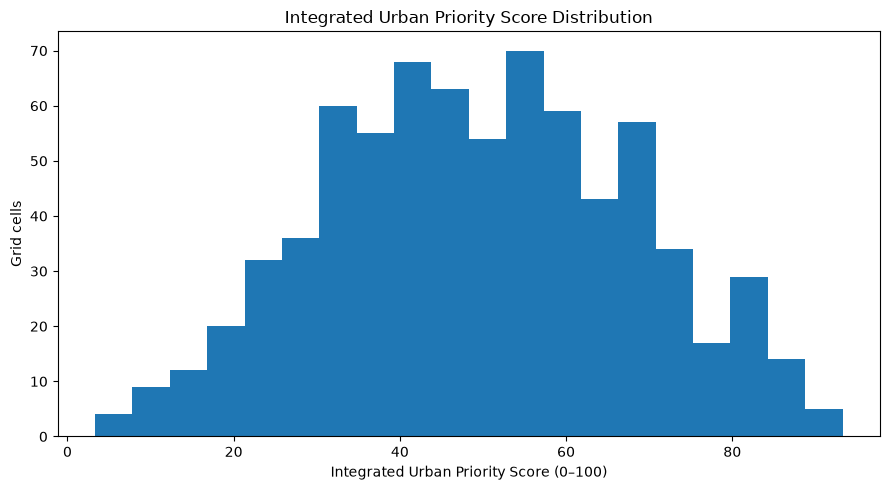

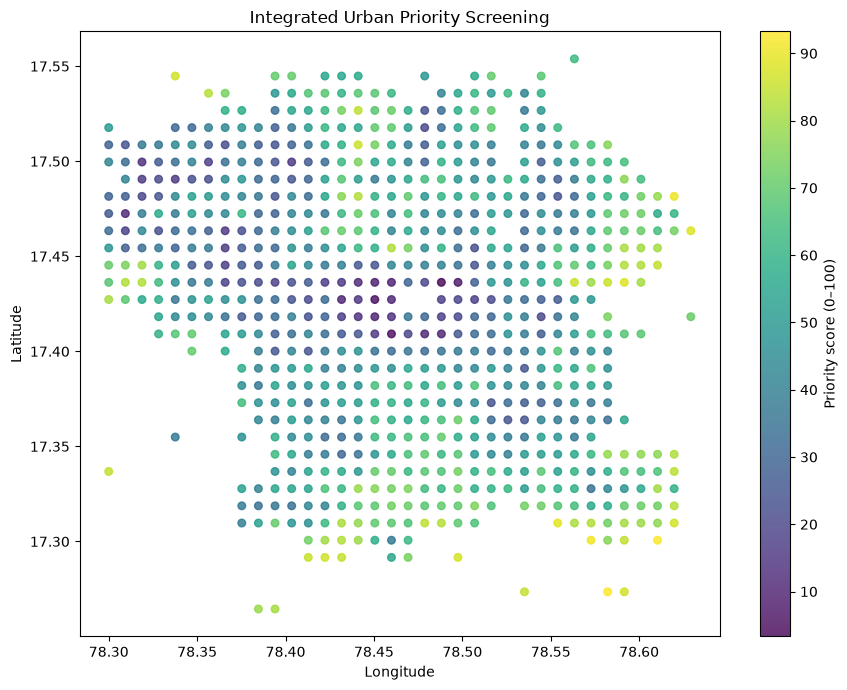

In [135]:
plt.figure(figsize=(9, 5))
plt.hist(integrated["priority_score_0_100"].dropna(), bins=20)
plt.xlabel("Integrated Urban Priority Score (0–100)")
plt.ylabel("Grid cells")
plt.title("Integrated Urban Priority Score Distribution")
plt.tight_layout()
plt.show()

if {"cell_center_latitude", "cell_center_longitude"}.issubset(integrated.columns):
    plt.figure(figsize=(9, 7))
    sc = plt.scatter(
        integrated["cell_center_longitude"],
        integrated["cell_center_latitude"],
        c=integrated["priority_score_0_100"],
        s=30, alpha=0.8
    )
    plt.colorbar(sc, label="Priority score (0–100)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("Integrated Urban Priority Screening")
    plt.tight_layout()
    plt.show()

## 15. Component explanation

The dashboard should show the component scores alongside the final score. This makes the prioritization explainable instead of a black box.

Component summary:


,mean_percentile_score,available_cells,coverage_percentage
flood_evidence_score,0.519231,26,3.29
heat_evidence_score,0.505988,741,93.68
infrastructure_gap_score,0.499368,791,100.00
road_representation_gap_score,0.499368,791,100.00


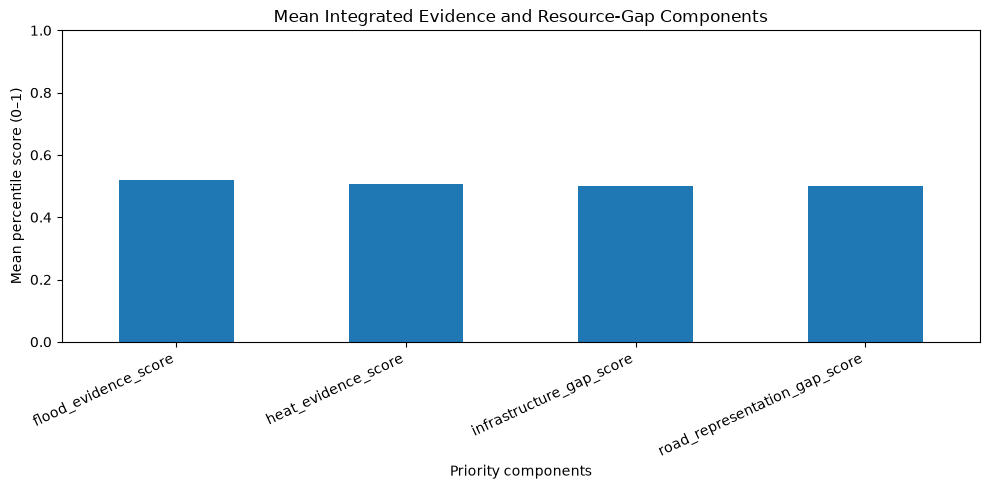

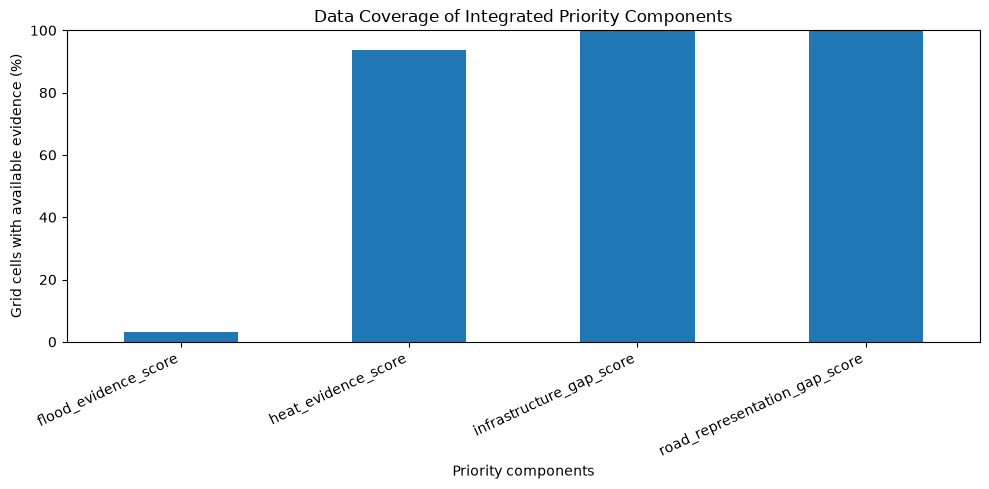

In [136]:

# -----------------------------------------
# COMPONENT EXPLANATION
# -----------------------------------------

component_cols = [
    "flood_evidence_score",
    "heat_evidence_score",
    "infrastructure_gap_score",
    "road_representation_gap_score"
]

available_components = [
    col for col in component_cols
    if col in integrated.columns
]


# -----------------------------------------
# 1. COMPONENT SUMMARY TABLE
# -----------------------------------------

if available_components:

    component_summary = pd.DataFrame({
        "mean_percentile_score": (
            integrated[available_components].mean()
        ),
        "available_cells": (
            integrated[available_components].count()
        ),
        "coverage_percentage": (
            integrated[available_components].count()
            / len(integrated) * 100
        )
    })

    component_summary["coverage_percentage"] = (
        component_summary["coverage_percentage"].round(2)
    )

    print("Component summary:")
    display(component_summary)


    # -----------------------------------------
    # 2. COMPONENT MEAN SCORE CHART
    # -----------------------------------------

    means = integrated[available_components].mean()

    plt.figure(figsize=(10, 5))

    means.plot(kind="bar")

    plt.ylabel("Mean percentile score (0–1)")
    plt.xlabel("Priority components")
    plt.title(
        "Mean Integrated Evidence and Resource-Gap Components"
    )

    plt.xticks(rotation=25, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()


    # -----------------------------------------
    # 3. COMPONENT DATA COVERAGE CHART
    # -----------------------------------------

    coverage = (
        integrated[available_components]
        .count()
        / len(integrated) * 100
    )

    plt.figure(figsize=(10, 5))

    coverage.plot(kind="bar")

    plt.ylabel("Grid cells with available evidence (%)")
    plt.xlabel("Priority components")
    plt.title("Data Coverage of Integrated Priority Components")

    plt.xticks(rotation=25, ha="right")
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.show()

else:
    print("No component score columns are available.")


## 16. Export dashboard-ready results

In [137]:

summary = {
    "grid_cells": int(len(integrated)),
    "grid_size_km": GRID_SIZE_KM,
    "spatial_assignment_method": "Nearest master-grid centre",
    "maximum_assignment_distance_km": MAX_ASSIGNMENT_DISTANCE_KM,

    "weights": WEIGHTS,

    "heat_sources": [
        "MODIS daytime temperature",
        "Yale daytime UHI"
    ],

    "score_interpretation": (
        "Relative screening and resource-prioritization indicator. "
        "Not a validated citywide risk prediction."
    ),

    "available_priority_scores": int(
        integrated["priority_score_0_100"].notna().sum()
    ),

    "hazard_evidence_cells": int(
        integrated["hazard_evidence_score"].notna().sum()
    ),

    "resource_context_gap_cells": int(
        integrated["resource_context_gap_score"].notna().sum()
    ),

    "limitations": [
        "OSM and infrastructure coverage may be incomplete.",
        "No mapped asset record does not prove that an asset is absent.",
        "Road data use representative points and do not provide road connectivity or travel time.",
        "Rainfall observations represent measured dates, not future flood predictions.",
        "Historical flood events without coordinates are not spatially assigned.",
        "MODIS temperature and Yale UHI are different measurements.",
        "Heat scores combine independently normalized source percentiles and are exploratory.",
        "Infrastructure and road gaps are relative mapped-data proxies, not validated service-adequacy measures.",
        "The 0.75 km assignment threshold is an approximate nearest-centre tolerance.",
        "Weights are analytical assumptions, not statistically validated risk weights."
    ]
}

csv_out = OUTPUT_ROOT / "integrated_urban_risk_priority_grid_1km.csv"
json_out = OUTPUT_ROOT / "integrated_urban_risk_summary.json"

integrated.to_csv(csv_out, index=False)

with open(json_out, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Saved:", csv_out)
print("Saved:", json_out)
print("Rows:", len(integrated))
print("Columns:", len(integrated.columns))


Saved: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\integrated_urban_risk\integrated_urban_risk_priority_grid_1km.csv
Saved: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\integrated_urban_risk\integrated_urban_risk_summary.json
Rows: 791
Columns: 66


In [143]:

# =============================================
# INTEGRATED URBAN RISK SYSTEM - EVALUATION METRICS
# =============================================

import numpy as np
import pandas as pd
from IPython.display import display

# 1. Overall score coverage
total_cells = len(integrated)
score_column = "priority_score_0_100"

scores = pd.to_numeric(integrated[score_column], errors="coerce")
valid_scores = scores.dropna()

scored_cells = len(valid_scores)
unscored_cells = total_cells - scored_cells

print("1. OVERALL SCORE COVERAGE")
print("--------------------------------")
print("Total grid cells:", total_cells)
print("Scored cells:", scored_cells)
print("Unscored cells:", unscored_cells)
print("Score coverage (%):",
      round(scored_cells / total_cells * 100, 2))

# 2. Priority score statistics
print("\n2. PRIORITY SCORE STATISTICS")
print("--------------------------------")
print("Minimum score:", round(valid_scores.min(), 3))
print("Maximum score:", round(valid_scores.max(), 3))
print("Mean score:", round(valid_scores.mean(), 3))
print("Median score:", round(valid_scores.median(), 3))
print("Standard deviation:", round(valid_scores.std(), 3))

# 3. Screening priority distribution
print("\n3. SCREENING PRIORITY DISTRIBUTION")
print("--------------------------------")

priority_distribution = (
    integrated["screening_priority"]
    .astype("object")
    .fillna("Not scored")
    .value_counts()
    .rename_axis("Priority Level")
    .reset_index(name="Number of Cells")
)

priority_distribution["Percentage (%)"] = (
    priority_distribution["Number of Cells"] / total_cells * 100
).round(2)

display(priority_distribution)

# 4. Individual component availability
print("\n4. COMPONENT DATA AVAILABILITY")
print("--------------------------------")

component_columns = [
    "flood_evidence_score",
    "heat_evidence_score",
    "infrastructure_gap_score",
    "road_representation_gap_score"
]

component_availability = pd.DataFrame({
    "Component": component_columns,
    "Available Cells": [
        integrated[col].notna().sum()
        for col in component_columns
    ]
})

component_availability["Coverage (%)"] = (
    component_availability["Available Cells"] / total_cells * 100
).round(2)

display(component_availability)

# 5. Number of score components available
print("\n5. SCORE COMPONENT COVERAGE")
print("--------------------------------")

display(
    integrated["priority_score_component_count"]
    .value_counts()
    .sort_index()
    .rename_axis("Available Components")
    .reset_index(name="Number of Cells")
)

# 6. Score validation
print("\n6. SCORE VALIDATION")
print("--------------------------------")

print("All scores are finite:",
      np.isfinite(valid_scores).all())

print("All scores are within 0-100:",
      valid_scores.between(0, 100).all())

print("Missing scores retained:",
      scores.isna().sum())

# 7. Final evaluation summary
print("\n7. FINAL EVALUATION SUMMARY")
print("--------------------------------")

print("Total cells:", total_cells)
print("Scored cells:", scored_cells)
print("Score coverage:", round(scored_cells / total_cells * 100, 2), "%")
print("Final score range:",
      round(valid_scores.min(), 3), "to",
      round(valid_scores.max(), 3))

print("\nEvaluation completed successfully.")

print("\nIMPORTANT:")
print("These are integrated-system coverage and consistency metrics.")
print("They are NOT classification accuracy or prediction accuracy.")
print("The priority score is a relative screening indicator,")
print("not a validated disaster probability.")


1. OVERALL SCORE COVERAGE
--------------------------------
Total grid cells: 791
Scored cells: 741
Unscored cells: 50
Score coverage (%): 93.68

2. PRIORITY SCORE STATISTICS
--------------------------------
Minimum score: 3.314
Maximum score: 93.275
Mean score: 49.613
Median score: 49.061
Standard deviation: 18.435

3. SCREENING PRIORITY DISTRIBUTION
--------------------------------


,Priority Level,Number of Cells,Percentage (%)
0,Moderate screening priority,310,39.19
1,Higher screening priority,294,37.17
2,Lower screening priority,72,9.10
3,Very high screening priority,65,8.22
4,Not scored,50,6.32



4. COMPONENT DATA AVAILABILITY
--------------------------------


,Component,Available Cells,Coverage (%)
0,flood_evidence_score,26,3.29
1,heat_evidence_score,741,93.68
2,infrastructure_gap_score,791,100.00
3,road_representation_gap_score,791,100.00



5. SCORE COMPONENT COVERAGE
--------------------------------


,Available Components,Number of Cells
0,0,50
1,3,715
2,4,26



6. SCORE VALIDATION
--------------------------------
All scores are finite: True
All scores are within 0-100: True
Missing scores retained: 50

7. FINAL EVALUATION SUMMARY
--------------------------------
Total cells: 791
Scored cells: 741
Score coverage: 93.68 %
Final score range: 3.314 to 93.275

Evaluation completed successfully.

IMPORTANT:
These are integrated-system coverage and consistency metrics.
They are NOT classification accuracy or prediction accuracy.
The priority score is a relative screening indicator,
not a validated disaster probability.


## 17. Final verification

Expected:
- one row per integrated grid cell
- score between 0 and 100
- confidence and screening band present
- no fabricated risk labels
- dashboard-ready CSV written

In [ ]:
assert integrated["grid_id"].is_unique
assert integrated["priority_score_0_100"].dropna().between(0, 100).all()
assert integrated["priority_confidence"].notna().all()
assert integrated["screening_priority"].notna().any()

print("FINAL VERIFICATION PASSED")
print("Grid cells:", len(integrated))
print("Score range:",
      integrated["priority_score_0_100"].min(),
      "to",
      integrated["priority_score_0_100"].max())
print("CSV:", csv_out)

FINAL VERIFICATION PASSED

Grid cells: 791
Priority scores available: 741
Cells without hazard evidence: 50
Cells with flood evidence: 26
Cells with heat evidence: 741
Priority score range: 3.3142674108601526 to 93.27530876203441

CSV: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\integrated_urban_risk\integrated_urban_risk_priority_grid_1km.csv
JSON: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\integrated_urban_risk\integrated_urban_risk_summary.json


# Final project interpretation

The integrated system does **not** claim to predict future disasters.

Instead, it combines heterogeneous spatial evidence into a transparent screening layer:

- **Flood evidence** → comparatively stronger observed rainfall evidence.
- **Heat evidence** → comparatively stronger measured daytime temperature/UHI evidence.
- **Infrastructure context** → mapped building/hospital availability and composition.
- **Road context** → mapped road representation and segment information.
- **Data confidence** → how much of the component evidence is actually available in each cell.

The **Integrated Urban Priority Score** ranks grid cells for investigation/resource-planning attention under the stated assumptions.

For the dashboard, display the final score together with component scores, confidence, and investigation flags. Do not call it an official disaster-risk probability.